In [1]:
%pylab inline
import scanpy as sc
import pandas as pd
import seaborn as sns
import numpy as np
import sys
sys.path.append('./helpers/')
import matplotlib.pyplot as plt

sc.settings.n_jobs = 45
sc._settings.ScanpyConfig.n_jobs = 45  # 保留10核给系统
sc._settings.ScanpyConfig.max_memory = 300  # GB，保留20G给系统

from matplotlib import *
import matplotlib.pyplot as plt
rcParams['pdf.fonttype']=42 # in order to save fonttype in AI
rcParams['ps.fonttype']=42

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


## ======================Plot excitatory neurons't data =======================

In [2]:
ad_Ext = sc.read('./h5ad/Ext.h5ad')
ad_Ext

AnnData object with n_obs × n_vars = 41681 × 20245
    obs: 'batch', 'Sex', 'TissueSample', 'BrainHemisphere', 'AutCtl', 'doublet_score', 'predicted_doublets', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'AnimalIDs', 'SampleIDs', 'Ages', 'cluster_IDs', 'cluster_labels', 'subClasses', 'classes'
    var: 'gene_ids', 'feature_types', 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'batch_colors', 'classes_colors', 'cluster_IDs_colors', 'cluster_labels_colors', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'rank_genes_groups', 'subClasses_colors', 'umap'
    obsm: 'X_harmonypca', 'X_pca', 'X_umap', 'X_umapharmony', 'X_umapraw'
    varm: 'PCs'
    layers: 'Counts'
    obsp: 'connectivities', 'distances'

/home/liu/anaconda3/envs/bioSoft/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/liu/anaconda3/envs/bioSoft/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


/home/liu/anaconda3/envs/bioSoft/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


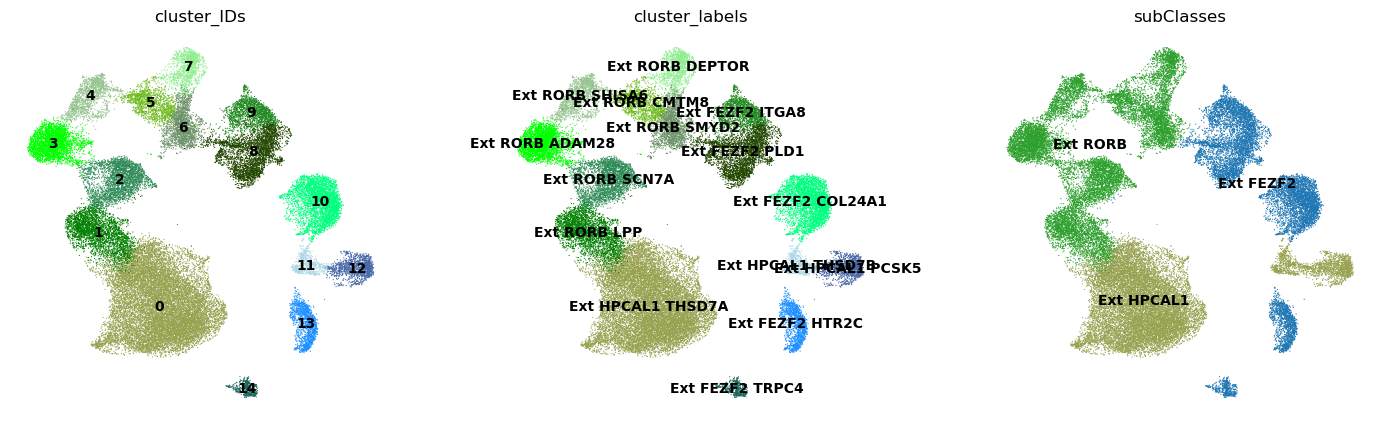

In [3]:
figsize(5,5)
sc.pl.umap(ad_Ext, color=['cluster_IDs','cluster_labels','subClasses'], legend_loc='on data', frameon=False, ncols=6, save='_Ext_Umaps.pdf')

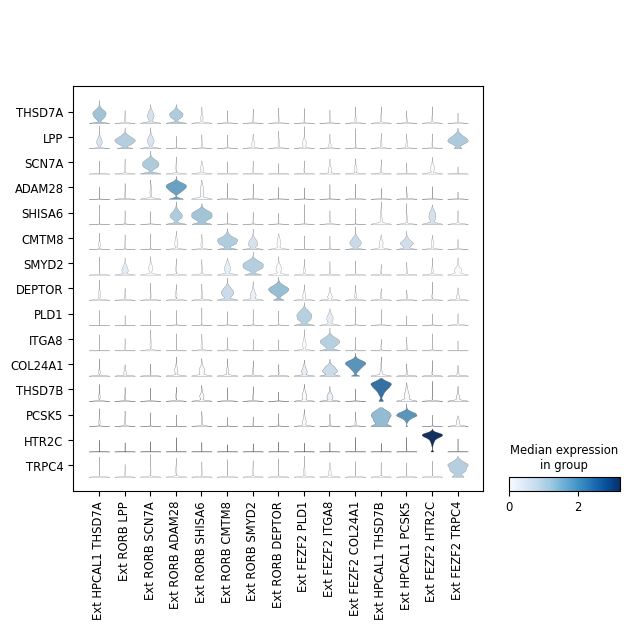

In [4]:
# Marker genes for each cell type
markerGenes = ['THSD7A',
               'LPP',     # CUX2
               'SCN7A',
               'ADAM28',
               'SHISA6',
               'CMTM8',
               'SMYD2',
               'DEPTOR',  # PTPRM
               'PLD1',
               'ITGA8',
               'COL24A1',  # NRP1, KAA1211, ADRA1A
               'THSD7B',   # RNF220, ADAMTSL1
               'PCSK5', 
               'HTR2C',    # NXPH2, SPON1, QRFPR
               'TRPC4',    # STXBP6, RIT2
              ]

sc.pl.stacked_violin(ad_Ext, markerGenes, groupby='cluster_labels',swap_axes = True,cmap='Blues', save='_Ext_markers.pdf')

In [5]:
del(ad_Ext)

## ======================Plot inhibitory neurons' data =======================

In [6]:
ad_Inh = sc.read('./h5ad/Inh.h5ad')
ad_Inh

AnnData object with n_obs × n_vars = 18853 × 20245
    obs: 'batch', 'Sex', 'TissueSample', 'BrainHemisphere', 'AutCtl', 'doublet_score', 'predicted_doublets', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'AnimalIDs', 'SampleIDs', 'Ages', 'cluster_IDs', 'cluster_labels', 'subClasses', 'classes'
    var: 'gene_ids', 'feature_types', 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'batch_colors', 'classes_colors', 'cluster_IDs_colors', 'cluster_labels_colors', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'rank_genes_groups', 'subClasses_colors', 'umap'
    obsm: 'X_harmonypca', 'X_pca', 'X_umap', 'X_umapharmony', 'X_umapraw'
    varm: 'PCs'
    layers: 'Counts'
    obsp: 'connectivities', 'distances'

/home/liu/anaconda3/envs/bioSoft/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/liu/anaconda3/envs/bioSoft/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/liu/anaconda3/envs/bioSoft/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


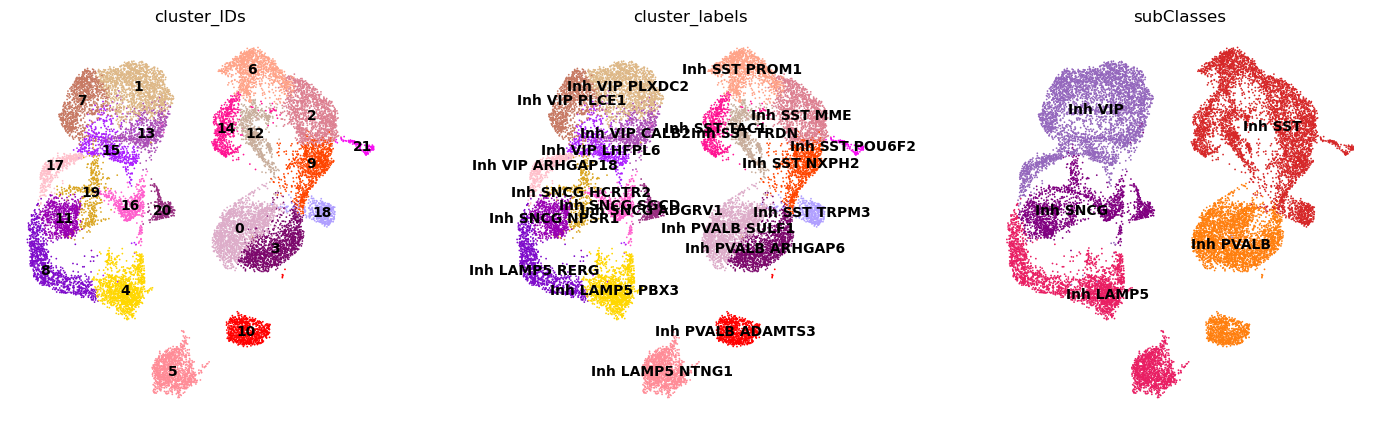

In [7]:
figsize(5,5)
sc.pl.umap(ad_Inh, color=['cluster_IDs','cluster_labels','subClasses'], legend_loc='on data', frameon=False, ncols=6, save='_Inh_Umaps.pdf')

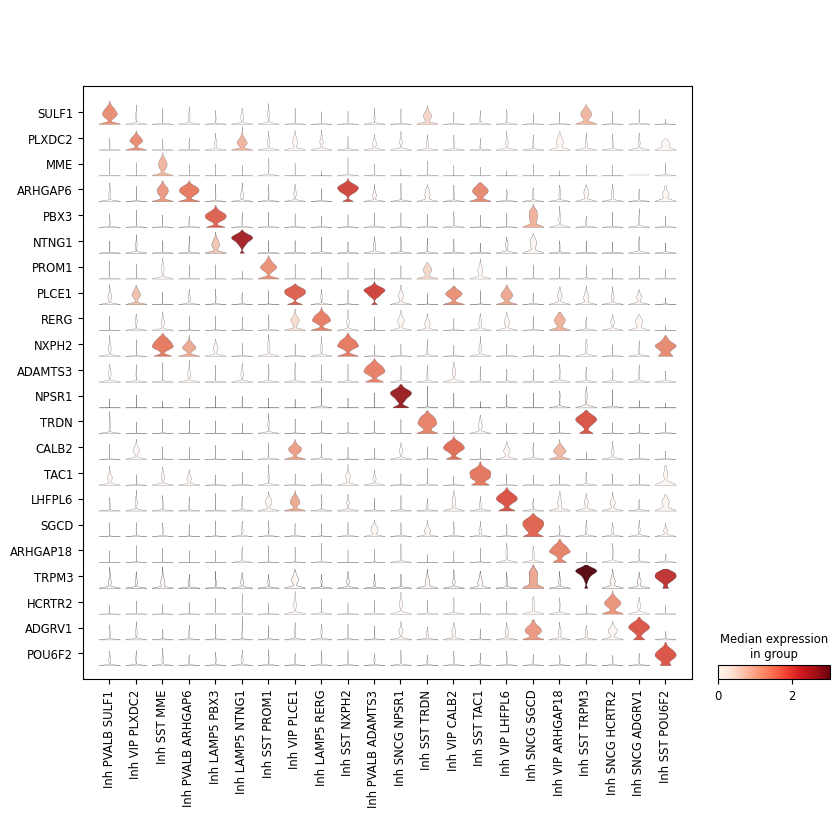

In [8]:
# Marker genes for each cell type
markerGenes = ['SULF1',  # 'POSTN','ETV6',''
               'PLXDC2',     # 
               'MME',  # SST
               'ARHGAP6',   # 'CCBE1'
               'PBX3',
               'NTNG1',   # FBN2  CPNE8
                'PROM1',  # CA10
               'PLCE1',  # 
               'RERG',
               'NXPH2',
               'ADAMTS3',  #  BPHA3  TRPS1
               'NPSR1',   # 
               'TRDN', 
               'CALB2',    # 
               'TAC1',    # 
               'LHFPL6',   # IQGAP2    15
               'SGCD',
               'ARHGAP18',  # 
               'TRPM3',   # 
               'HCRTR2', #  'CADPS2', 
               'ADGRV1',    # 
               'POU6F2',    #
              ]

sc.pl.stacked_violin(ad_Inh, markerGenes, groupby='cluster_labels', swap_axes = True, cmap='Reds', save='_Inh_markers.pdf')

In [9]:
del(ad_Inh)

## ======================Plot the whole dataset figures =======================

In [10]:
ad_AIC = sc.read('./h5ad/ad_AIC_final.h5ad')
ad_AIC

AnnData object with n_obs × n_vars = 60534 × 20245
    obs: 'batch', 'Sex', 'TissueSample', 'BrainHemisphere', 'AutCtl', 'doublet_score', 'predicted_doublets', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'AnimalIDs', 'SampleIDs', 'Ages', 'cellClass', 'cellSubClass', 'cluster_IDs', 'cluster_labels'
    var: 'gene_ids', 'feature_types', 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'batch_colors', 'cellClass_colors', 'cellSubClass_colors', 'cluster_IDs_colors', 'cluster_labels_colors', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'umap'
    obsm: 'X_harmonypca', 'X_pca', 'X_umap', 'X_umapharmony', 'X_umapraw'
    varm: 'PCs'
    layers: 'Counts'
    obsp: 'connectivities', 'distances'

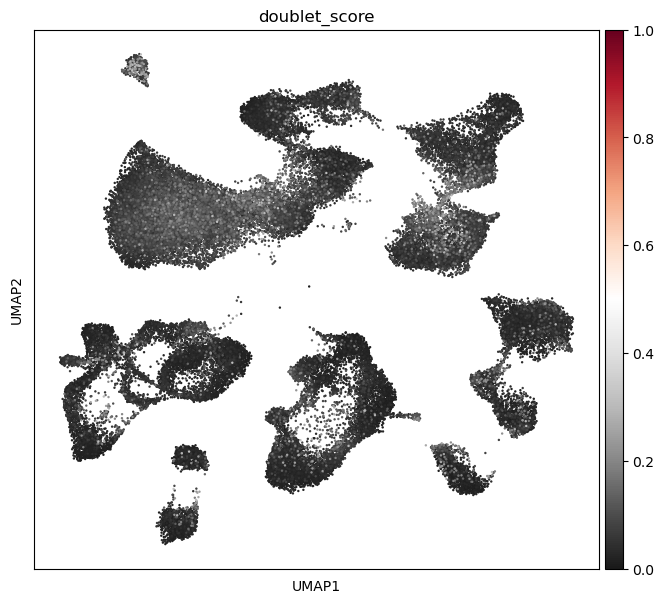

In [11]:
figsize(8,7)
sc.pl.umap(ad_AIC,color=['doublet_score'],vmin=0,vmax=1.0, size=12, cmap = 'RdGy_r',save='_doubleletScore_AIC.pdf')# 'RdGy_r',)

/home/liu/anaconda3/envs/bioSoft/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


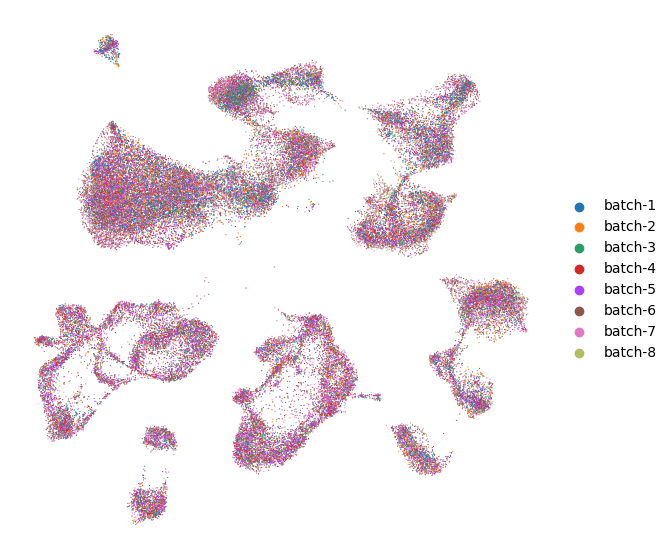

In [12]:
figsize(7,7)
sc.pl.umap(ad_AIC,color=['batch'],vmin=0,vmax=1.0, size=3, frameon='', title='', cmap = 'RdGy_r',save='_batchDistribution_allCells_AIC.pdf')

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


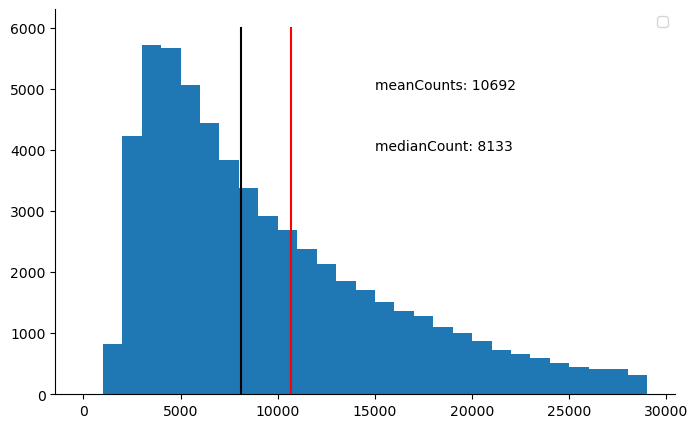

In [13]:
# of cells relative to the UMI counts
figsize(8,5)
nCells_hist = hist(ad_AIC.obs['total_counts'],bins=range(0,30000,1000))
meanCounts = np.mean(ad_AIC.obs['total_counts'])
medianCount = np.median(ad_AIC.obs['total_counts'])
# add figure properties.
ax = plt.gca()
ylim= ax.get_ylim()
ax.plot([meanCounts,meanCounts],ylim,c='r')
ax.plot([medianCount,medianCount],ylim,c='k')
ax.text(15000,5000, f'meanCounts: {meanCounts:.0f}')
ax.text(15000,4000, f'medianCount: {medianCount:.0f}')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.legend(loc='upper right')

plt.savefig("figures/UMIcountsDistribution_AIC.pdf", dpi = 600)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


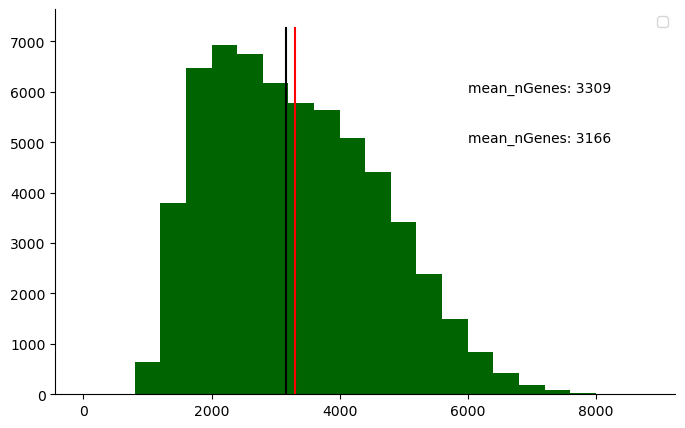

In [14]:
# of cells relative to the detected genes
figsize(8,5)
nCells_hist = hist(ad_AIC.obs['n_genes'],bins=range(0,9000,400),color = 'darkgreen')
mean_nGenes = np.mean(ad_AIC.obs['n_genes'])
median_nGenes = np.median(ad_AIC.obs['n_genes'])
# add figure properties.
ax = plt.gca()
ylim= ax.get_ylim()
ax.plot([mean_nGenes,mean_nGenes],ylim,c='r')
ax.plot([median_nGenes,median_nGenes],ylim,c='k')
ax.text(6000, 6000, f'mean_nGenes: {mean_nGenes:.0f}')
ax.text(6000, 5000, f'mean_nGenes: {median_nGenes:.0f}')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.legend(loc='upper right')

plt.savefig("figures/detectedGenesDistribution_AIC.pdf", dpi = 600)

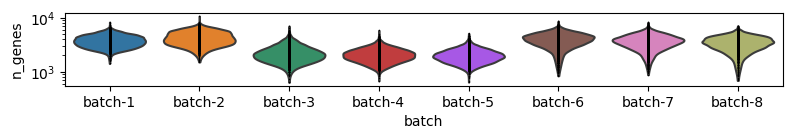

In [15]:
# plot the detected genes in each sample
figsize(8,1)
sc.pl.violin(ad_AIC,'n_genes',groupby='batch',log=True, jitter=False, color='g',save='detectedGenes_eachSample_AIC.pdf')

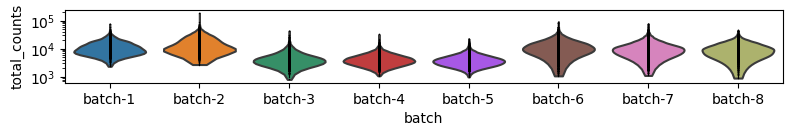

In [16]:
# plot the total counts in each sample
figsize(8,1)
ax = sc.pl.violin(ad_AIC,'total_counts',groupby='batch',log=True, jitter=False,color='g',save='suppl_totalCounts_eachSample_AIC.pdf')

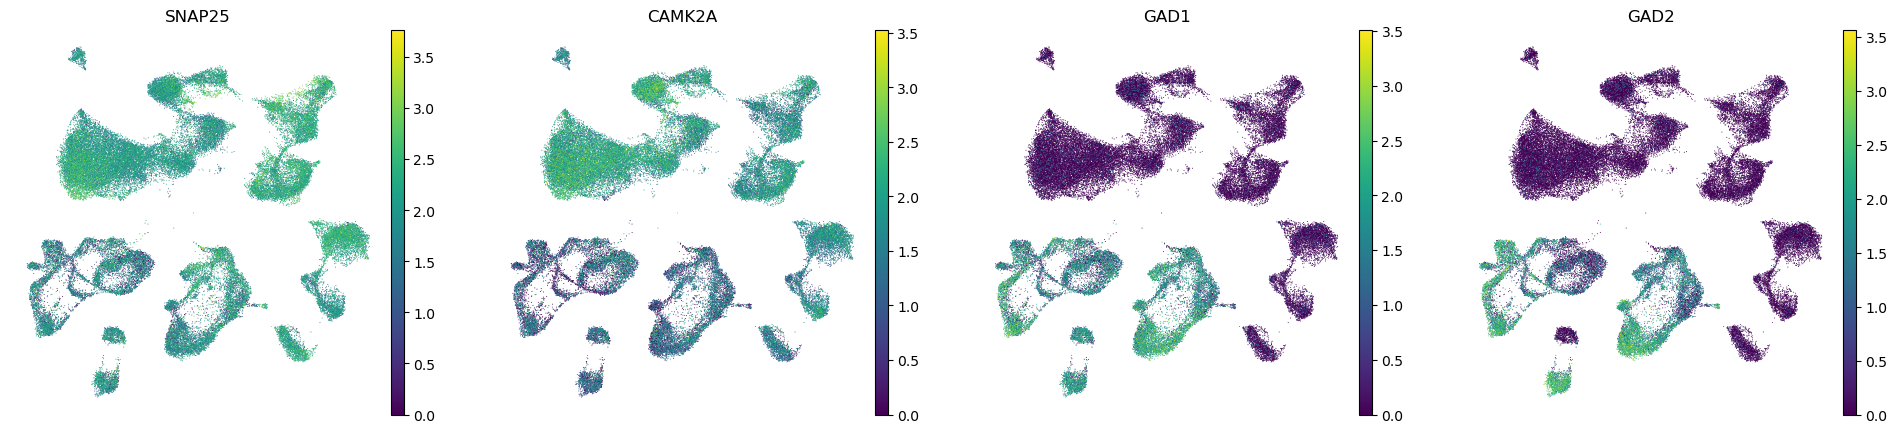

In [17]:
figsize(5,5)
sc.pl.umap(ad_AIC, color=['SNAP25','CAMK2A','GAD1','GAD2'], legend_loc='on data', frameon=False, ncols=6, save='_AIC_neurons_Umaps.pdf')

/home/liu/anaconda3/envs/bioSoft/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:749: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds)


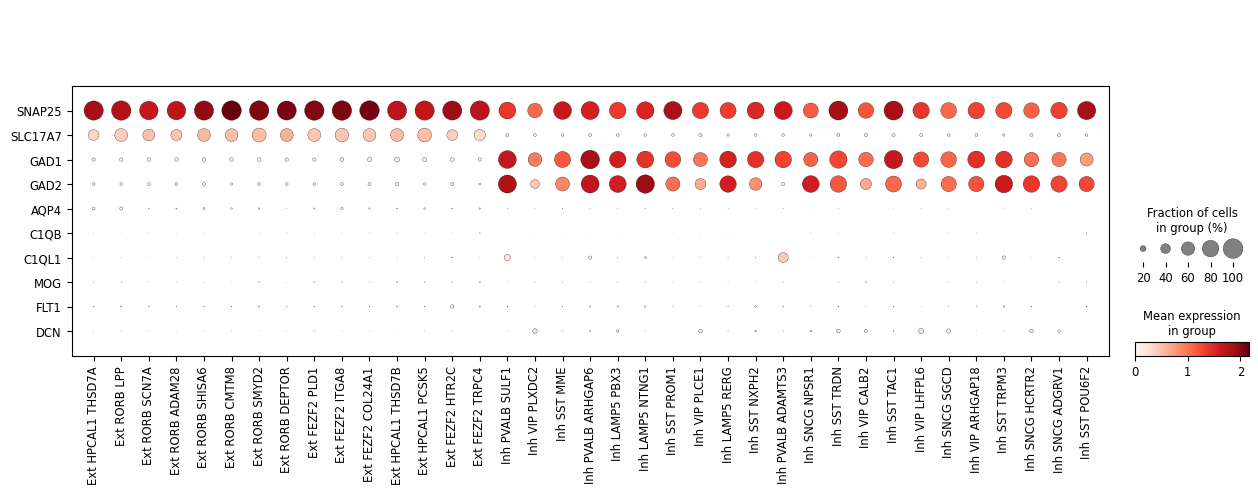

In [18]:
plot_genes = ['SNAP25','SLC17A7','GAD1','GAD2','AQP4','C1QB', 'C1QL1','MOG','FLT1','DCN']
sc.pl.dotplot(ad_AIC, var_names = plot_genes, groupby = 'cluster_labels', swap_axes = True, edgecolor='k', dendrogram = False, save='_allClusters.pdf')

In [19]:
ad_AIC.obs['cluster_labels'].cat.categories

Index(['Ext HPCAL1 THSD7A', 'Ext RORB LPP', 'Ext RORB SCN7A',
       'Ext RORB ADAM28', 'Ext RORB SHISA6', 'Ext RORB CMTM8',
       'Ext RORB SMYD2', 'Ext RORB DEPTOR', 'Ext FEZF2 PLD1',
       'Ext FEZF2 ITGA8', 'Ext FEZF2 COL24A1', 'Ext HPCAL1 THSD7B',
       'Ext HPCAL1 PCSK5', 'Ext FEZF2 HTR2C', 'Ext FEZF2 TRPC4',
       'Inh PVALB SULF1', 'Inh VIP PLXDC2', 'Inh SST MME', 'Inh PVALB ARHGAP6',
       'Inh LAMP5 PBX3', 'Inh LAMP5 NTNG1', 'Inh SST PROM1', 'Inh VIP PLCE1',
       'Inh LAMP5 RERG', 'Inh SST NXPH2', 'Inh PVALB ADAMTS3',
       'Inh SNCG NPSR1', 'Inh SST TRDN', 'Inh VIP CALB2', 'Inh SST TAC1',
       'Inh VIP LHFPL6', 'Inh SNCG SGCD', 'Inh VIP ARHGAP18', 'Inh SST TRPM3',
       'Inh SNCG HCRTR2', 'Inh SNCG ADGRV1', 'Inh SST POU6F2'],
      dtype='object')

In [20]:
cluster_Names_2_newOrder = ad_AIC.obs['cluster_labels'].cat.categories

In [21]:
cell_label_reorder = cluster_Names_2_newOrder
# cell_label_reorder
cell_counts = pd.DataFrame(ad_AIC.obs['cluster_labels'].value_counts())
# cell_counts = cell_counts.reindex(cell_label_reorder)

cell_label = ad_AIC.obs['cluster_labels'].cat.categories
cell_color = list(ad_AIC.uns['cluster_labels_colors'])

In [22]:
heatmap_color = dict(zip(cell_label,cell_color))

In [23]:
cell_cat = cell_label_reorder 
cell_counts = pd.DataFrame(ad_AIC.obs['cluster_labels'].value_counts())
cell_counts = cell_counts.reindex(cell_cat)

# width of the bars
barWidth = 1
cell_type_all = list(cell_counts.index)    # becase the sequence distinction between ad.obs['cluster_Names_2'].cat.categories and ad.obs['cellType_labels_2'].cat.categories. we have to reorder the cellTpe labels in cell_type_all same as that in cellTypeID_2.

bar_color = dict(zip(cell_label,cell_color))
bar_color= pd.DataFrame.from_dict(heatmap_color, orient = 'index', columns = ['color'])
bar_color = bar_color.reindex(cell_label_reorder)

bars_original = np.array(cell_counts['cluster_labels'])
#bars1 = np.log10(bars_original)
bars1 = np.log10(bars_original)
#bars2 = mmmk_corr_rho.loc[key,:]
#bars3 = mmhu_HGNC_corr_rho.loc[cluster_key,gene_sets]

# The x position of bars
r1 = np.arange(len(bars1))
#r2 = [x + barWidth for x in r1]
#r3 = [x + barWidth + 0.05 for x in r1]
#p = humk_HGNC_corr_p_dif.loc[cluster_key,gene_sets] 

/tmp/ipykernel_7548/2739207501.py:13: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(cell_type_all,rotation=90,size=8)


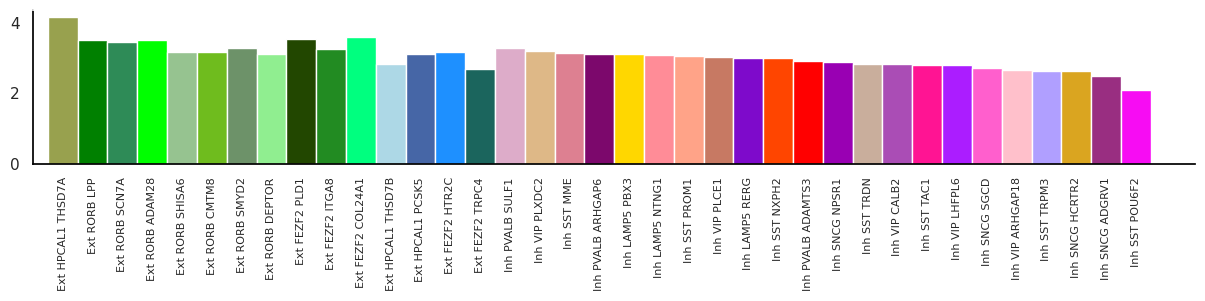

In [24]:
fig = plt.figure(figsize = (15,2))
plt.rcParams['font.size'] = '2'
    
gs = GridSpec(1, 1, figure=fig)
sns.set(font_scale=1)
    
    
ax = fig.add_subplot(gs[0, 0])
# Create bars
ax.bar(r1, bars1, width = barWidth, color = bar_color['color'])
# general layout
ax.set_yticks([0,2,4]) 
ax.set_xticklabels(cell_type_all,rotation=90,size=8)
ax.set_xticks(np.arange(len(cell_type_all)))
 
ax.set_xlim([-1,38])
# # Show graphic
# #plt.show()
ax.set_facecolor('white')
ax.spines['bottom'].set_color('#000000')
ax.spines['left'].set_color('#000000') 

plt.savefig("figures/cellCounts4EachCellType_AIC.pdf", dpi = 600)

In [25]:
subCellTypeIDs = np.sort(ad_AIC.obs['cluster_IDs'].cat.codes.unique())
subCellTypeIDs
nSample = len(np.sort(ad_AIC.obs['TissueSample'].cat.codes.unique()))
nSample

8

In [26]:
n_cells = np.zeros([nSample,len(subCellTypeIDs)])
for sample in range(nSample):
    sampleData = ad_AIC[ad_AIC.obs['batch']=='batch-'+str(sample+1)]
    for subCellTypeID in subCellTypeIDs:
        n_cells[sample,subCellTypeID] = np.sum(sampleData.obs['cluster_IDs']==subCellTypeID)
 
    # n_cells[sample] = n_cells[sample]/np.sum(n_cells[sample,:])
nCell_percent = np.zeros([nSample,len(subCellTypeIDs)])
for sample in range(nSample):
    nCell_percent[sample] = n_cells[sample]/np.sum(n_cells[sample,:])
    

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


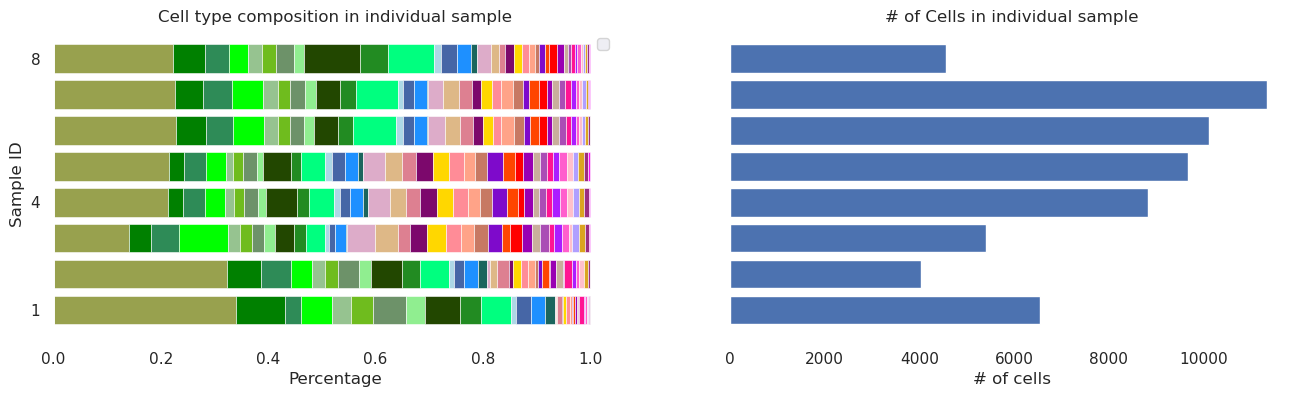

<Figure size 500x500 with 0 Axes>

In [27]:
fig, axs = plt.subplots(1,2, figsize=(16,4), sharey=True)
width = 0.8
for i in range(len(subCellTypeIDs)):
    axs[0].barh(range(1,9,1), nCell_percent[:,i], width, left = np.sum(nCell_percent[:,:i],axis=1), color=bar_color['color'][ ad_AIC.obs['cluster_labels'].cat.categories[i]  ],linewidth=0.4)

axs[0].set_title("Cell type composition in individual sample")
axs[0].spines['right'].set_visible(True)
axs[0].spines['top'].set_visible(True)
axs[0].legend(loc="best")
axs[0].set_xlabel('Percentage')
axs[0].set_ylabel('Sample ID')
axs[0].set_facecolor('white')
axs[0].set_yticks([1, 4, 8])

# plot the number of cells in each sample
n_cells_sample = np.sum(n_cells,axis=1)
n_cells_sample
axs[1].barh(range(1,9,1),n_cells_sample, width, left=0)
axs[1].set_title("# of Cells in individual sample")
axs[1].spines['right'].set_visible(True)
axs[1].spines['top'].set_visible(True)
axs[1].set_xlabel('# of cells')
axs[1].set_facecolor('white')
axs[1].set_yticks([1, 4, 8])
plt.show()

plt.savefig("figures/Fig_NrCellsStat_eachSample.pdf", dpi = 600)

In [28]:
# Prepare the number of cells in each cell type.
n_cellTypesAllSample = np.sum(n_cells,axis=0)
n_cellTypes = np.zeros(9)
n_cellTypes[0] = np.sum(n_cellTypesAllSample[0:14])
n_cellTypes[1] = np.sum(n_cellTypesAllSample[15:36])

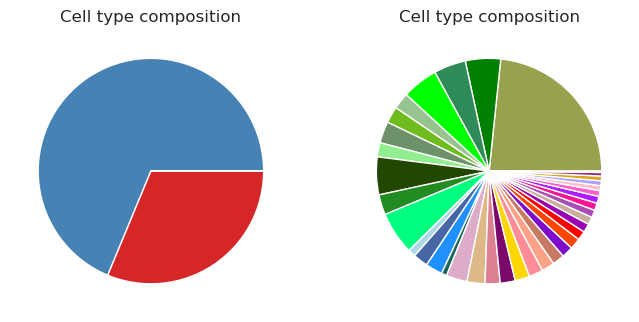

<Figure size 2000x1200 with 0 Axes>

In [29]:
# reorder the colors
clusterOrder = ad_AIC.obs['cluster_labels'].cat.categories
bar_color = bar_color.reindex(clusterOrder)

# Pie plot of the cell type composition.
size = 0.15
cmap = plt.colormaps["tab20c"]
outer_colors = ['steelblue','#d62728',]

figsize(8,4)
fig, axs = plt.subplots(1,2)
plt.figure(figsize=(20, 12))
axs[0].pie(n_cellTypes, colors=outer_colors, )
       # wedgeprops=dict(width=0.3, edgecolor='w'))
axs[0].set(aspect="equal", title='Cell type composition')

axs[1].pie(n_cellTypesAllSample, colors=bar_color['color'], )
       # wedgeprops=dict(width=0.3, edgecolor='w'))
axs[1].set(aspect="equal", title='Cell type composition')
plt.show()

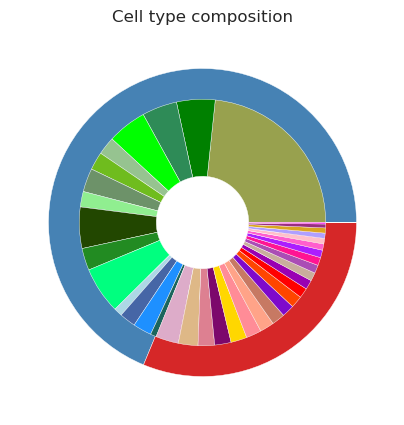

In [30]:
# Pie plot of the cell type composition.
size = 0.2
lineW = 0.3
cmap = plt.colormaps["tab20c"]
outer_colors = ['steelblue','#d62728']

inner_colors = cmap(range(36))

figsize(5,5)
fig, ax = plt.subplots()
ax.pie(n_cellTypes, radius=1, colors=outer_colors,
       wedgeprops=dict(width=0.5, edgecolor='w',linewidth=lineW))
ax.pie(n_cellTypesAllSample, radius=1-size, colors=bar_color['color'], 
       wedgeprops=dict(width=0.5, edgecolor='w',linewidth=lineW))
ax.set(aspect="equal", title='Cell type composition')

# plt.show()
fig.savefig("figures/subclustersCountsPie_AIC.pdf", dpi = 600)

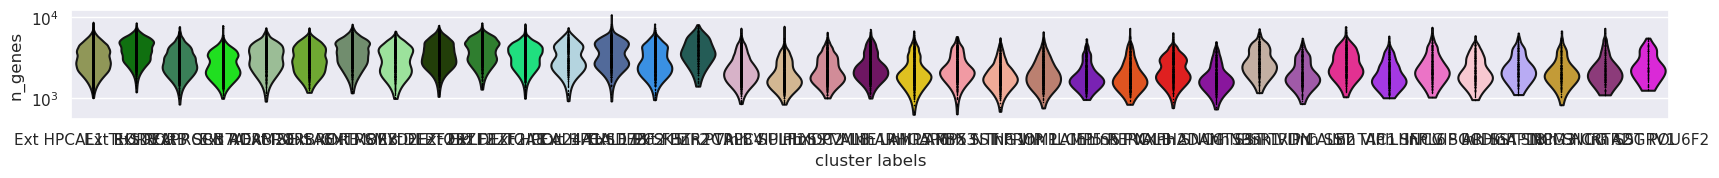

In [31]:
# plot the detected genes in each cell cluster.
figsize(16,1.5)
sc.pl.violin(ad_AIC,'n_genes',groupby='cluster_labels',log=True, jitter=False,color=bar_color['color'],save='detectedGenes_eachClass_AIC.pdf')

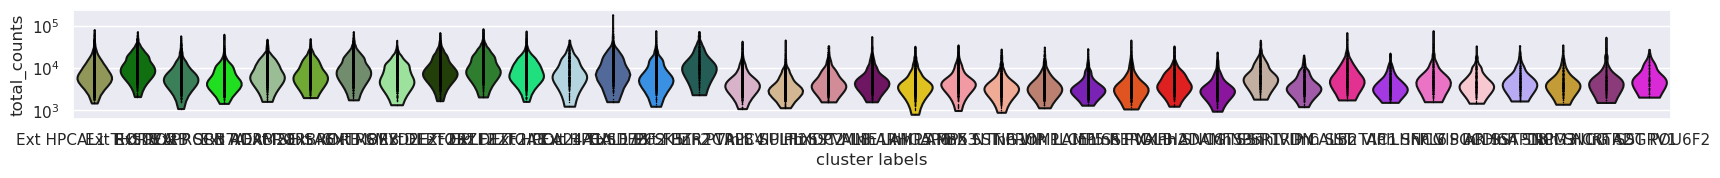

In [32]:
# plot the detected genes in each cell cluster.
figsize(16,1.5)
sc.pl.violin(ad_AIC,'total_counts',groupby='cluster_labels',log=True, jitter=False,color=bar_color['color'],save='totalCounts_eachClass_AIC.pdf')